# Machine report

The condition of one machine over the last hours of its recording.

This notebook holds no logic of its own: the numbers come from `pdm_workshop.reports`, the same functions used by `scripts/machine_report.py` and by the `fleet` command. To report on another machine, change the two values in the second cell and choose **Restart and Run All**.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from pdm_workshop.plotting import MUTED_COLOR, apply_style
from pdm_workshop.reports import load_feature_table, machine_report

apply_style()

In [2]:
MACHINE = "M07"
HOURS = 100

## The numbers

Five equal bands, oldest first. A relative value of 1.0 means "as in the first snapshots of this machine".

In [3]:
table = load_feature_table()
machine_report(table, MACHINE, HOURS)

hours_before_end,snapshots,temperature_c,rms_rel,high_band_ratio_rel
f64,u32,f64,f32,f32
100.0,10,61.1,1.01,0.96
80.0,10,62.6,0.99,1.11
60.0,10,64.5,1.04,1.47
40.0,10,68.5,1.24,1.85
20.0,10,73.6,1.48,2.41


## The trend

The same two relative features, snapshot by snapshot. Both are ratios to the healthy state, so they share one axis.

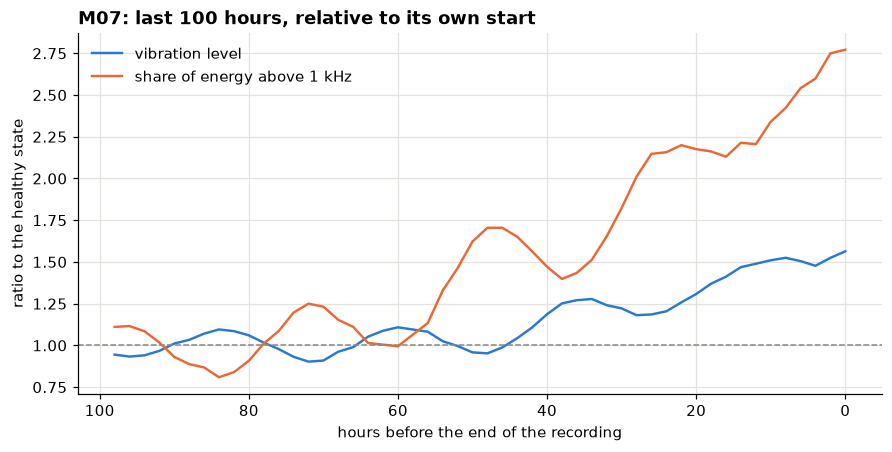

In [4]:
recent = table.filter((pl.col("machine_id") == MACHINE) & (pl.col("rul_hours") < HOURS))
hours_before_end = recent["rul_hours"].to_numpy()

fig, ax = plt.subplots()
ax.plot(hours_before_end, recent["rms_rel"].to_numpy(), label="vibration level")
ax.plot(
    hours_before_end,
    recent["high_band_ratio_rel"].to_numpy(),
    label="share of energy above 1 kHz",
)
ax.axhline(1.0, color=MUTED_COLOR, linewidth=1.0, linestyle="--")
ax.invert_xaxis()
ax.set(
    title=f"{MACHINE}: last {HOURS} hours, relative to its own start",
    xlabel="hours before the end of the recording",
    ylabel="ratio to the healthy state",
)
ax.legend()
plt.show()

## How to read it

- Values that stay close to 1.0 mean the machine still behaves as it did at the start.
- The share of energy above 1 kHz usually moves first; the overall level follows.
- Temperature also follows the daily load cycle, so judge it over a whole band, not from one reading.